# Exploratory Data Analysis

## Imports and Configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure notebook output
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIRECTORY = PROJECT_ROOT / "data" / "generated"

TELEMETRY_PATH = DATA_DIRECTORY / "synthetic_telemetry.csv"
DEVICES_PATH = DATA_DIRECTORY / "device_registry.csv"
COMMANDS_PATH = DATA_DIRECTORY / "synthetic_commands.csv"

required_files = [
    TELEMETRY_PATH,
    DEVICES_PATH,
    COMMANDS_PATH,
]

missing_files = [
    path for path in required_files
    if not path.exists()
]

if missing_files:
    missing_paths = "\n".join(str(path) for path in missing_files)

    raise FileNotFoundError(
        "The following Phase 2 datasets could not be found:\n"
        f"{missing_paths}\n"
        "Run the Phase 2 data-generation notebook first."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Data Directory: {DATA_DIRECTORY}")
print("All required Datasets were Found")

Project Root: /Users/quendrew/Desktop/Smart-X-ML
Data Directory: /Users/quendrew/Desktop/Smart-X-ML/data/generated
All required Datasets were Found


## Load Datasets

In [2]:
# Parse timestamps
telemetry_df = pd.read_csv(
    TELEMETRY_PATH,
    parse_dates=["timestamp"],
)

devices_df = pd.read_csv(DEVICES_PATH)

commands_df = pd.read_csv(
    COMMANDS_PATH,
    parse_dates=["timestamp"],
)

# Summarise the size of each Dataset
dataset_overview = pd.DataFrame(
    {
        "dataset": [
            "Telemetry",
            "Device registry",
            "Commands",
        ],
        "rows": [
            len(telemetry_df),
            len(devices_df),
            len(commands_df),
        ],
        "columns": [
            len(telemetry_df.columns),
            len(devices_df.columns),
            len(commands_df.columns),
        ],
    }
)

display(dataset_overview)

# Inspect records from each dataset
print("Telemetry preview")
display(telemetry_df.head())

print("Device registry preview")
display(devices_df.head())

print("Command history preview")
display(commands_df.head())

,dataset,rows,columns
0,Telemetry,34560,15
1,Device registry,12,6
2,Commands,154,11


Telemetry preview


,timestamp,device_id,node_id,zone,device_category,temperature_c,humidity_pct,moisture_pct,water_ph,water_ec_ms_cm,water_flow_l_min,device_health,battery_pct,pump_active,fan_active
0,2026-01-01 00:00:00+00:00,SX-ENV-001,NF-001,ZONE-A,Environmental,23.29,71.41,49.59,NaN,NaN,NaN,0.974,100.00,False,False
1,2026-01-01 00:15:00+00:00,SX-ENV-001,NF-001,ZONE-A,Environmental,23.07,67.39,50.87,NaN,NaN,NaN,0.926,100.00,False,False
2,2026-01-01 00:30:00+00:00,SX-ENV-001,NF-001,ZONE-A,Environmental,22.57,64.92,45.83,NaN,NaN,NaN,0.961,100.00,False,False
3,2026-01-01 00:45:00+00:00,SX-ENV-001,NF-001,ZONE-A,Environmental,24.00,72.27,47.24,NaN,NaN,NaN,0.973,98.87,False,False
4,2026-01-01 01:00:00+00:00,SX-ENV-001,NF-001,ZONE-A,Environmental,22.81,67.66,49.91,NaN,NaN,NaN,0.959,100.00,False,False


Device registry preview


,device_id,node_id,zone,device_category,baseline_health,device_status
0,SX-ENV-001,NF-001,ZONE-A,Environmental,0.965,ONLINE
1,SX-ENV-002,NF-002,ZONE-A,Environmental,0.928,ONLINE
2,SX-ENV-003,NF-003,ZONE-A,Environmental,0.974,ONLINE
3,SX-WTR-001,NF-004,ZONE-A,Water Management,0.957,ONLINE
4,SX-WTR-002,NF-005,ZONE-A,Water Management,0.890,ONLINE


Command history preview


,command_id,timestamp,device_id,node_id,zone,action,trigger_temperature_c,trigger_humidity_pct,trigger_moisture_pct,trigger_device_health,trigger_battery_pct
0,CMD-000001,2026-01-01 04:15:00+00:00,SX-ENV-003,NF-003,ZONE-A,ACTIVATE_FAN,30.39,62.69,60.42,0.965,99.85
1,CMD-000002,2026-01-01 10:15:00+00:00,SX-ENV-003,NF-003,ZONE-A,DEACTIVATE_FAN,24.75,63.50,62.04,0.973,98.53
2,CMD-000003,2026-01-02 03:15:00+00:00,SX-ENV-006,NF-008,ZONE-B,ACTIVATE_PUMP,24.21,65.49,34.53,0.965,100.00
3,CMD-000004,2026-01-02 05:30:00+00:00,SX-ENV-003,NF-003,ZONE-A,ACTIVATE_FAN,30.01,71.04,59.53,0.964,97.63
4,CMD-000005,2026-01-02 05:30:00+00:00,SX-ENV-006,NF-008,ZONE-B,DEACTIVATE_PUMP,21.74,68.16,61.14,0.977,99.66


## Initial structural Checks

In [3]:
# Review column names, inferred data types, and non null record counts
print("Telemetry schema")
telemetry_df.info()

print("\nDevice registry schema")
devices_df.info()

print("\nCommand history schema")
commands_df.info()

# Confirm the Expected device and Telemetry Coverage
print("\nCoverage summary")
print(f"Registered Devices: {devices_df['device_id'].nunique():,}")
print(f"Devices with Telemetry: {telemetry_df['device_id'].nunique():,}")
print(f"Telemetry Start: {telemetry_df['timestamp'].min()}")
print(f"Telemetry End: {telemetry_df['timestamp'].max()}")
print(f"Recorded Command Events: {len(commands_df):,}")

Telemetry schema
<class 'pandas.DataFrame'>
RangeIndex: 34560 entries, 0 to 34559
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   timestamp         34560 non-null  datetime64[us, UTC]
 1   device_id         34560 non-null  str                
 2   node_id           34560 non-null  str                
 3   zone              34560 non-null  str                
 4   device_category   34560 non-null  str                
 5   temperature_c     34560 non-null  float64            
 6   humidity_pct      34560 non-null  float64            
 7   moisture_pct      34560 non-null  float64            
 8   water_ph          14400 non-null  float64            
 9   water_ec_ms_cm    14400 non-null  float64            
 10  water_flow_l_min  14400 non-null  float64            
 11  device_health     34560 non-null  float64            
 12  battery_pct       34560 non-null  float64            


## Missing Value Assessment

In [4]:
# Summarise Missing values in each Dataset
def missing_value_report(dataframe: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    """Return missing value counts and percentages for each column."""
    report = pd.DataFrame({
        "column": dataframe.columns,
        "missing_count": dataframe.isna().sum().values,
        "missing_percentage": (
            dataframe.isna().mean().values * 100
        ).round(2),
    })

    report.insert(0, "dataset", dataset_name)

    return report.sort_values(
        "missing_count",
        ascending=False,
    ).reset_index(drop=True)


missing_report = pd.concat(
    [
        missing_value_report(telemetry_df, "Telemetry"),
        missing_value_report(devices_df, "Device registry"),
        missing_value_report(commands_df, "Commands"),
    ],
    ignore_index=True,
)

display(
    missing_report.loc[
        missing_report["missing_count"] > 0
    ]
)

print("Columns with missing values:", 
      missing_report.loc[
          missing_report["missing_count"] > 0
      ].shape[0])

,dataset,column,missing_count,missing_percentage
0,Telemetry,water_ph,20160,58.33
1,Telemetry,water_ec_ms_cm,20160,58.33
2,Telemetry,water_flow_l_min,20160,58.33


Columns with missing values: 3


## Validate category specific missing Values

In [5]:
water_measurement_columns = [
    "water_ph",
    "water_ec_ms_cm",
    "water_flow_l_min",
]

environmental_mask = telemetry_df["device_category"].eq("Environmental")
water_management_mask = telemetry_df["device_category"].eq("Water Management")

category_missing_report = []

for category, mask in [
    ("Environmental", environmental_mask),
    ("Water Management", water_management_mask),
]:
    for column in water_measurement_columns:
        category_missing_report.append({
            "device_category": category,
            "measurement": column,
            "missing_count": int(telemetry_df.loc[mask, column].isna().sum()),
            "total_readings": int(mask.sum()),
        })

category_missing_df = pd.DataFrame(category_missing_report)

category_missing_df["missing_percentage"] = (
    category_missing_df["missing_count"]
    / category_missing_df["total_readings"].replace(0, np.nan)
    * 100
).round(2)

display(category_missing_df)

unexpected_missing_values = (
    telemetry_df.loc[environmental_mask, water_measurement_columns]
    .notna()
    .sum()
    .sum()
    +
    telemetry_df.loc[water_management_mask, water_measurement_columns]
    .isna()
    .sum()
    .sum()
)

print(
    "Unexpected water-measurement missingness or presence:",
    int(unexpected_missing_values),
)

,device_category,measurement,missing_count,total_readings,missing_percentage
0,Environmental,water_ph,20160,20160,100.0
1,Environmental,water_ec_ms_cm,20160,20160,100.0
2,Environmental,water_flow_l_min,20160,20160,100.0
3,Water Management,water_ph,0,14400,0.0
4,Water Management,water_ec_ms_cm,0,14400,0.0
5,Water Management,water_flow_l_min,0,14400,0.0


Unexpected water-measurement missingness or presence: 0


## Duplicate Checks

In [6]:
# Count Duplicate records using the Identifiers that should be unique
duplicate_checks = pd.DataFrame([
    {
        "check": "Duplicate device registrations",
        "duplicate_count": int(devices_df["device_id"].duplicated().sum()),
    },
    {
        "check": "Duplicate telemetry rows",
        "duplicate_count": int(telemetry_df.duplicated().sum()),
    },
    {
        "check": "Duplicate telemetry device/timestamp pairs",
        "duplicate_count": int(
            telemetry_df.duplicated(["device_id", "timestamp"]).sum()
        ),
    },
    {
        "check": "Duplicate command identifiers",
        "duplicate_count": int(commands_df["command_id"].duplicated().sum()),
    },
])

display(duplicate_checks)

,check,duplicate_count
0,Duplicate device registrations,0
1,Duplicate telemetry rows,0
2,Duplicate telemetry device/timestamp pairs,0
3,Duplicate command identifiers,0


## Measurement and Temporal Validation

## Sensor Range Checks

In [7]:
# Expected simulated range for each numeric measurement
sensor_ranges = {
    "temperature_c": (-10, 60),
    "humidity_pct": (0, 100),
    "moisture_pct": (0, 100),
    "water_ph": (0, 14),
    "water_ec_ms_cm": (0, 10),
    "water_flow_l_min": (0, 100),
    "device_health": (0, 1),
    "battery_pct": (0, 100),
}

range_results = []

for column, (lower_bound, upper_bound) in sensor_ranges.items():
    values = telemetry_df[column].dropna()

    below_range = int((values < lower_bound).sum())
    above_range = int((values > upper_bound).sum())

    range_results.append({
        "measurement": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "valid_observations": len(values),
        "below_range": below_range,
        "above_range": above_range,
        "minimum_observed": values.min() if not values.empty else np.nan,
        "maximum_observed": values.max() if not values.empty else np.nan,
    })

sensor_range_report = pd.DataFrame(range_results)

display(sensor_range_report)

,measurement,lower_bound,upper_bound,valid_observations,below_range,above_range,minimum_observed,maximum_observed
0,temperature_c,-10,60,34560,0,0,15.000,35.23
1,humidity_pct,0,100,34560,0,0,44.970,83.67
2,moisture_pct,0,100,34560,0,0,22.310,73.73
3,water_ph,0,14,14400,0,0,5.440,6.54
4,water_ec_ms_cm,0,10,14400,0,0,1.010,2.54
5,water_flow_l_min,0,100,14400,0,0,0.230,2.19
6,device_health,0,1,34560,0,0,0.837,1.00
7,battery_pct,0,100,34560,0,0,81.930,100.00


## Timestamp and Sampling Checks

In [8]:
# Confirm timestamps are Valid
timestamp_report = {
    "telemetry_missing_timestamps": int(telemetry_df["timestamp"].isna().sum()),
    "commands_missing_timestamps": int(commands_df["timestamp"].isna().sum()),
    "telemetry_chronologically_sorted": bool(
        telemetry_df["timestamp"].is_monotonic_increasing
    ),
    "commands_chronologically_sorted": bool(
        commands_df["timestamp"].is_monotonic_increasing
    ),
}

display(
    pd.DataFrame(
        timestamp_report.items(),
        columns=["check", "result"],
    )
)

# Inspect intervals between consecutive readings for each device
ordered_telemetry = telemetry_df.sort_values(
    ["device_id", "timestamp"]
).copy()

ordered_telemetry["interval_minutes"] = (
    ordered_telemetry.groupby("device_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
)

sampling_report = (
    ordered_telemetry.groupby("device_id")["interval_minutes"]
    .agg(["count", "min", "median", "max"])
    .reset_index()
)

display(sampling_report)

unexpected_intervals = ordered_telemetry.loc[
    ordered_telemetry["interval_minutes"].notna()
    & ~np.isclose(
        ordered_telemetry["interval_minutes"],
        15.0,
    )
]

print(
    "Unexpected Telemetry intervals:",
    len(unexpected_intervals),
)

,check,result
0,telemetry_missing_timestamps,0
1,commands_missing_timestamps,0
2,telemetry_chronologically_sorted,False
3,commands_chronologically_sorted,True


,device_id,count,min,median,max
0,SX-ENV-001,2879,15.0,15.0,15.0
1,SX-ENV-002,2879,15.0,15.0,15.0
2,SX-ENV-003,2879,15.0,15.0,15.0
3,SX-ENV-004,2879,15.0,15.0,15.0
4,SX-ENV-005,2879,15.0,15.0,15.0
5,SX-ENV-006,2879,15.0,15.0,15.0
6,SX-ENV-007,2879,15.0,15.0,15.0
7,SX-WTR-001,2879,15.0,15.0,15.0
8,SX-WTR-002,2879,15.0,15.0,15.0
9,SX-WTR-003,2879,15.0,15.0,15.0


Unexpected Telemetry intervals: 0


## Referential Integrity

In [9]:
# Every telemetry and Command device identifier should exist in the registry
registered_device_ids = set(devices_df["device_id"])

telemetry_device_ids = set(telemetry_df["device_id"])
command_device_ids = set(commands_df["device_id"])

unknown_telemetry_devices = telemetry_device_ids - registered_device_ids
unknown_command_devices = command_device_ids - registered_device_ids

# Verify that node, zone, and category attributes agree with the registry.
registry_lookup = devices_df.set_index("device_id")

telemetry_registry = telemetry_df[
    ["device_id", "node_id", "zone", "device_category"]
].drop_duplicates()

telemetry_registry_check = telemetry_registry.join(
    registry_lookup[["node_id", "zone", "device_category"]],
    on="device_id",
    rsuffix="_registered",
)

attribute_mismatch_count = 0

for column in ["node_id", "zone", "device_category"]:
    attribute_mismatch_count += int(
        (
            telemetry_registry_check[column]
            != telemetry_registry_check[f"{column}_registered"]
        ).sum()
    )

integrity_report = pd.DataFrame([
    {
        "check": "Unknown telemetry device IDs",
        "issue_count": len(unknown_telemetry_devices),
    },
    {
        "check": "Unknown command device IDs",
        "issue_count": len(unknown_command_devices),
    },
    {
        "check": "Telemetry registry attribute mismatches",
        "issue_count": attribute_mismatch_count,
    },
])

display(integrity_report)

,check,issue_count
0,Unknown telemetry device IDs,0
1,Unknown command device IDs,0
2,Telemetry registry attribute mismatches,0


## Overall Data Quality Summary

In [11]:
quality_summary = pd.DataFrame([
    {
        "check": "Duplicate device registrations",
        "issue_count": int(devices_df["device_id"].duplicated().sum()),
    },
    {
        "check": "Duplicate telemetry device/timestamp pairs",
        "issue_count": int(
            telemetry_df.duplicated(["device_id", "timestamp"]).sum()
        ),
    },
    {
        "check": "Duplicate command identifiers",
        "issue_count": int(commands_df["command_id"].duplicated().sum()),
    },
    {
        "check": "Unexpected sensor range violations",
        "issue_count": int(
            sensor_range_report["below_range"].sum()
            + sensor_range_report["above_range"].sum()
        ),
    },
    {
        "check": "Unexpected telemetry sampling intervals",
        "issue_count": len(unexpected_intervals),
    },
    {
        "check": "Unknown telemetry device IDs",
        "issue_count": len(unknown_telemetry_devices),
    },
    {
        "check": "Unknown command device IDs",
        "issue_count": len(unknown_command_devices),
    },
    {
        "check": "Telemetry registry attribute mismatches",
        "issue_count": attribute_mismatch_count,
    },
])

display(quality_summary)

print(
    "Assessment Complete"
)

,check,issue_count
0,Duplicate device registrations,0
1,Duplicate telemetry device/timestamp pairs,0
2,Duplicate command identifiers,0
3,Unexpected sensor range violations,0
4,Unexpected telemetry sampling intervals,0
5,Unknown telemetry device IDs,0
6,Unknown command device IDs,0
7,Telemetry registry attribute mismatches,0


Assessment Complete


## Device Coverage

In [12]:
# Summarise device Distribution across categories and deployment zones
display(
    devices_df.groupby(["zone", "device_category"])
    .size()
    .unstack(fill_value=0)
)

# Count telemetry readings contributed by each device
device_coverage = (
    telemetry_df.groupby(["device_id", "zone", "device_category"])
    .size()
    .reset_index(name="reading_count")
    .sort_values("reading_count", ascending=False)
)

display(device_coverage)

device_category,Environmental,Water Management
zone,,
ZONE-A,3,2
ZONE-B,3,2
ZONE-C,1,1


,device_id,zone,device_category,reading_count
0,SX-ENV-001,ZONE-A,Environmental,2880
1,SX-ENV-002,ZONE-A,Environmental,2880
2,SX-ENV-003,ZONE-A,Environmental,2880
3,SX-ENV-004,ZONE-B,Environmental,2880
4,SX-ENV-005,ZONE-B,Environmental,2880
5,SX-ENV-006,ZONE-B,Environmental,2880
6,SX-ENV-007,ZONE-C,Environmental,2880
7,SX-WTR-001,ZONE-A,Water Management,2880
8,SX-WTR-002,ZONE-A,Water Management,2880
9,SX-WTR-003,ZONE-B,Water Management,2880


## Sensor Statistics

In [13]:
# Summarise central tendency, variability, and Observed ranges
sensor_columns = [
    "temperature_c",
    "humidity_pct",
    "moisture_pct",
    "water_ph",
    "water_ec_ms_cm",
    "water_flow_l_min",
    "device_health",
    "battery_pct",
]

display(
    telemetry_df[sensor_columns]
    .describe()
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
temperature_c,34560.0,23.741,2.971,15.000,21.600,23.710,25.870,35.23
humidity_pct,34560.0,64.650,5.486,44.970,61.220,65.220,68.490,83.67
moisture_pct,34560.0,52.372,6.721,22.310,47.500,52.310,57.330,73.73
water_ph,14400.0,5.999,0.157,5.440,5.890,6.010,6.110,6.54
water_ec_ms_cm,14400.0,1.779,0.215,1.010,1.630,1.790,1.930,2.54
water_flow_l_min,14400.0,1.199,0.252,0.230,1.030,1.200,1.370,2.19
device_health,34560.0,0.946,0.035,0.837,0.921,0.953,0.974,1.00
battery_pct,34560.0,96.010,3.723,81.930,93.520,97.060,99.200,100.00


## Sensor Distributions

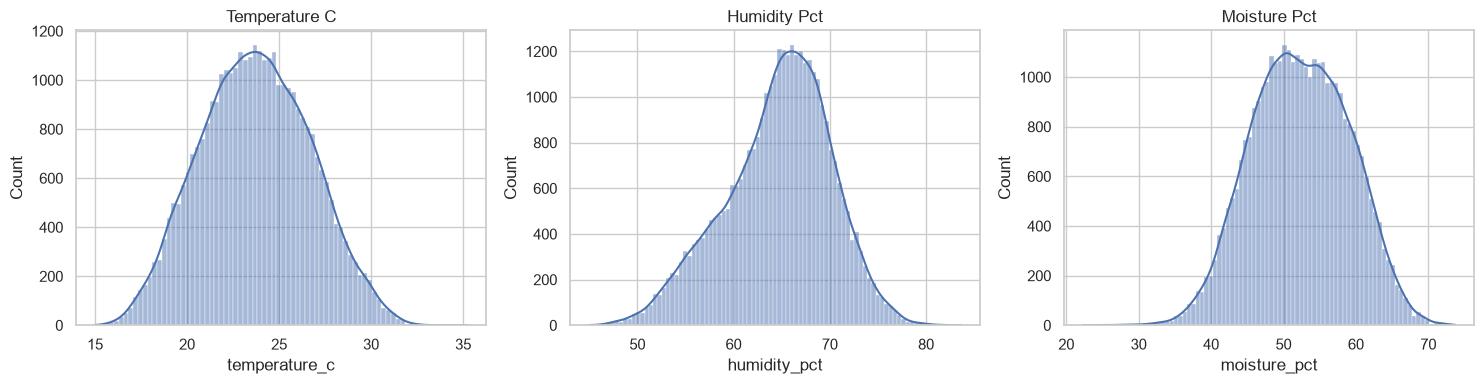

In [14]:
# Compare the Distributions
environmental_columns = [
    "temperature_c",
    "humidity_pct",
    "moisture_pct",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for column, axis in zip(environmental_columns, axes):
    sns.histplot(
        data=telemetry_df,
        x=column,
        kde=True,
        ax=axis,
    )
    axis.set_title(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

## Environmental Readings over time

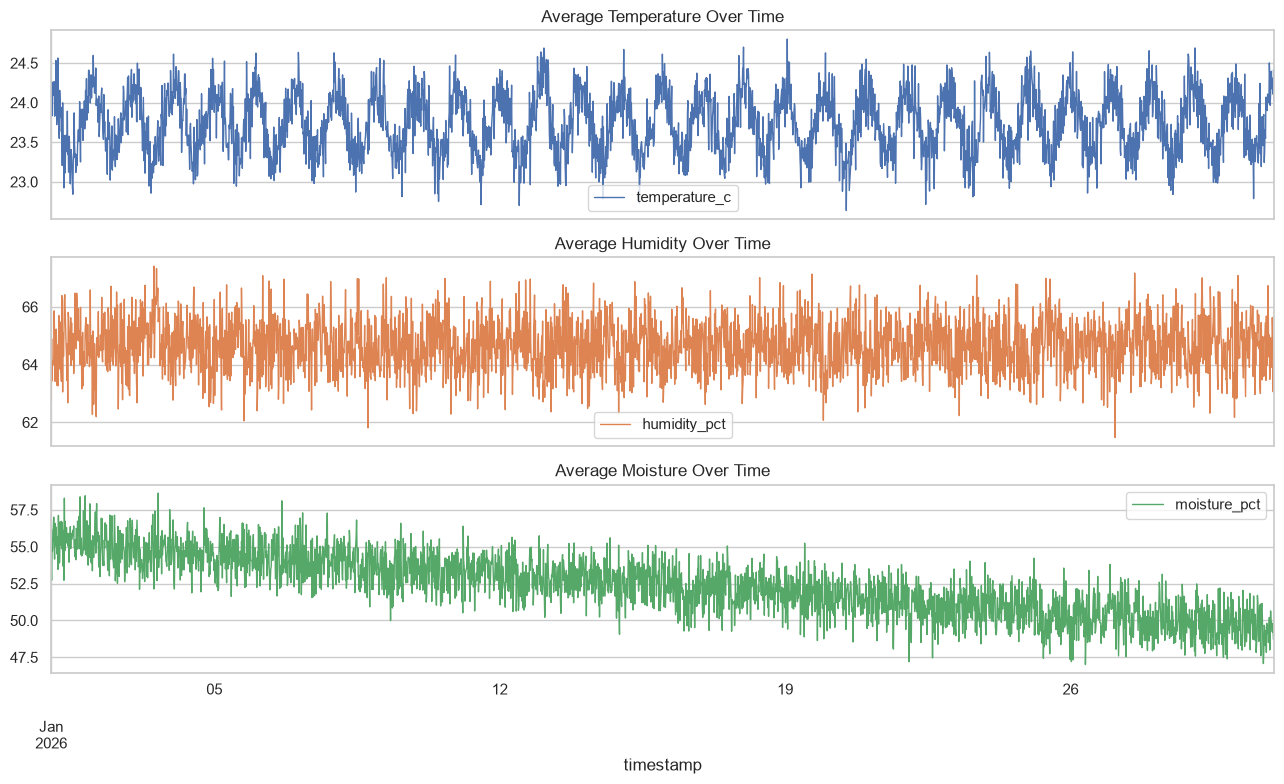

In [15]:
# Aggregate Readings by timestamp
environmental_trends = (
    telemetry_df.groupby("timestamp")[environmental_columns]
    .mean()
)

environmental_trends.plot(
    subplots=True,
    figsize=(13, 8),
    linewidth=1,
    title=[
        "Average Temperature Over Time",
        "Average Humidity Over Time",
        "Average Moisture Over Time",
    ],
)

plt.tight_layout()
plt.show()

## Compare Zones

,temperature_c,humidity_pct,moisture_pct
zone,,,
ZONE-A,25.03,66.22,54.27
ZONE-B,22.92,62.57,49.67
ZONE-C,22.57,65.92,54.38


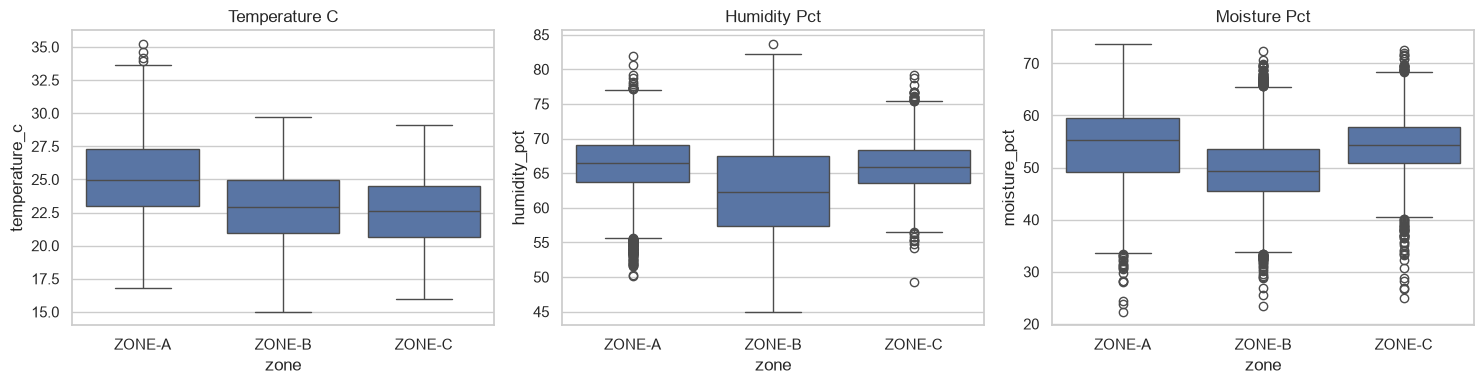

In [16]:
# Compare average environmental Conditions across Deployment zones
zone_summary = (
    telemetry_df.groupby("zone")[
        ["temperature_c", "humidity_pct", "moisture_pct"]
    ]
    .mean()
    .round(2)
)

display(zone_summary)

# Visualise the distribution of each measurement across zones.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for column, axis in zip(
    ["temperature_c", "humidity_pct", "moisture_pct"],
    axes,
):
    sns.boxplot(data=telemetry_df, x="zone", y=column, ax=axis)
    axis.set_title(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

## Compare sensor conditions by Action

In [18]:
# Compare telemetry conditions recorded when each command was generated
condition_columns = [
    "trigger_temperature_c",
    "trigger_humidity_pct",
    "trigger_moisture_pct",
    "trigger_device_health",
    "trigger_battery_pct",
]

action_condition_summary = (
    commands_df.groupby("action")[condition_columns]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(action_condition_summary)

trigger_temperature_c                             trigger_humidity_pct                              \
                                count   mean median    min    max                count   mean median    min    max   
action                                                                                                               
ACTIVATE_FAN                       61  30.09  30.30  21.64  31.50                   61  66.43  66.14  57.02  83.67   
ACTIVATE_PUMP                      18  22.20  21.56  18.63  26.79                   18  63.83  64.38  53.38  72.70   
DEACTIVATE_FAN                     60  25.22  25.48  20.74  26.00                   60  66.95  67.81  61.90  69.99   
DEACTIVATE_PUMP                    15  22.28  22.09  17.11  25.66                   15  62.10  62.54  50.89  70.14   

                trigger_moisture_pct                             trigger_device_health                           \
                               count   mean median    min    max                 count  mean median   min   max   
action                                                                                                            
ACTIVATE_FAN                      61  54.83  56.85  39.55  64.77                    61  0.97   0.97  0.93  1.00   
ACTIVATE_PUMP                     18  33.08  34.18  26.66  34.99                    18  0.96   0.96  0.92  1.00   
DEACTIVATE_FAN                    60  53.58  54.04  41.21  63.61                    60  0.97   0.97  0.93  1.00   
DEACTIVATE_PUMP                   15  57.32  56.58  55.00  63.45                    15  0.96   0.96  0.92  0.98   

                trigger_battery_pct                              
                              count   mean median    min    max  
action                                                           
ACTIVATE_FAN                     61  95.49  95.72  82.99  100.0  
ACTIVATE_PUMP                    18  93.96  92.58  86.81  100.0  
DEACTIVATE_FAN                   60  95.23  96.34  85.06  100.0  
DEACTIVATE_PUMP                  15  94.97  95.10  86.69  100.0

## Visualise key Sesor - Action relationships

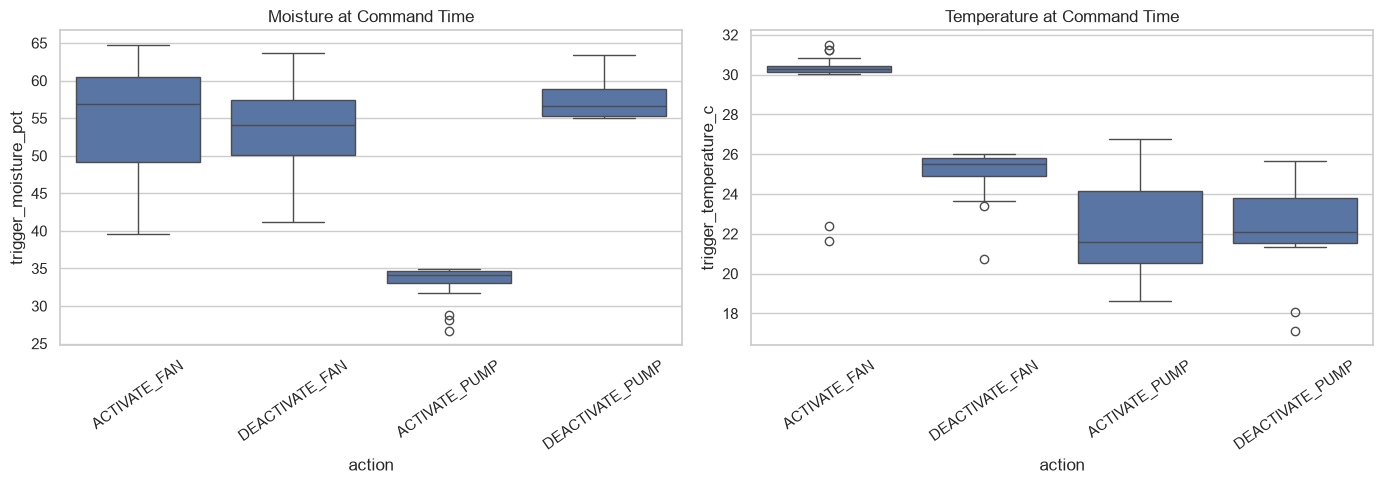

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=commands_df,
    x="action",
    y="trigger_moisture_pct",
    ax=axes[0],
)
axes[0].set_title("Moisture at Command Time")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(
    data=commands_df,
    x="action",
    y="trigger_temperature_c",
    ax=axes[1],
)
axes[1].set_title("Temperature at Command Time")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## Summarise action Conditions

In [20]:
# Calculate median sensor conditions
action_medians = (
    commands_df.groupby("action")[
        condition_columns
    ]
    .median()
    .round(2)
)

display(action_medians)

,trigger_temperature_c,trigger_humidity_pct,trigger_moisture_pct,trigger_device_health,trigger_battery_pct
action,,,,,
ACTIVATE_FAN,30.30,66.14,56.85,0.97,95.72
ACTIVATE_PUMP,21.56,64.38,34.18,0.96,92.58
DEACTIVATE_FAN,25.48,67.81,54.04,0.97,96.34
DEACTIVATE_PUMP,22.09,62.54,56.58,0.96,95.10


## Correlation and Anomaly Analysis

## Correlation Heatmap

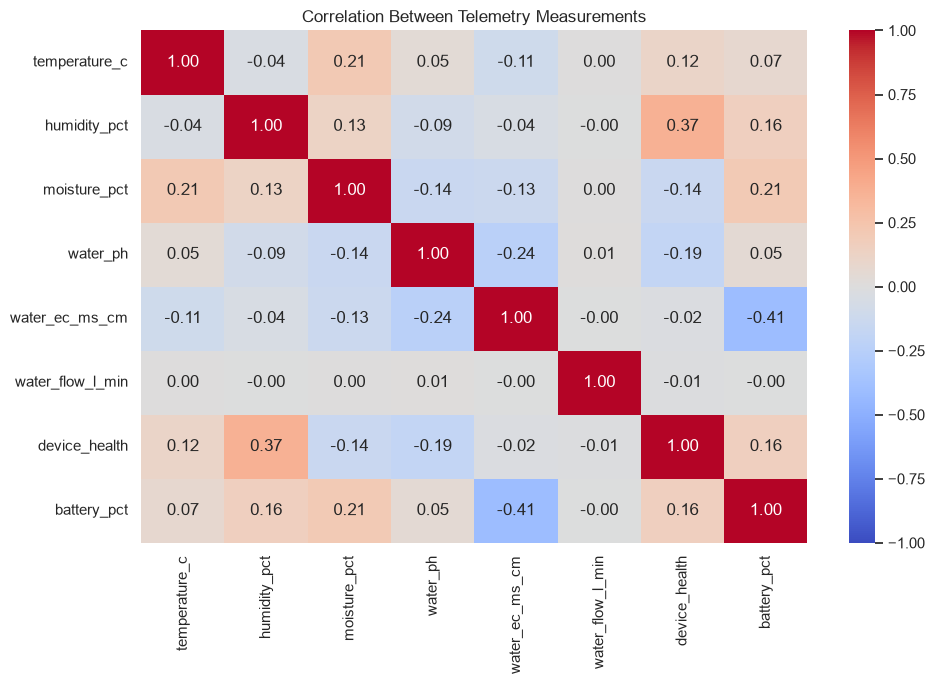

In [21]:
# Select numeric sensor measurements
sensor_columns = [
    "temperature_c",
    "humidity_pct",
    "moisture_pct",
    "water_ph",
    "water_ec_ms_cm",
    "water_flow_l_min",
    "device_health",
    "battery_pct",
]

correlation_matrix = telemetry_df[sensor_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Between Telemetry Measurements")
plt.tight_layout()
plt.show()

##  Inspect Extreme Readings

In [22]:
# Display the lowest and highest observations for key measurements
for column in ["temperature_c", "humidity_pct", "moisture_pct", "device_health"]:
    print(f"\nLowest {column} readings")
    display(
        telemetry_df.nsmallest(3, column)[
            ["timestamp", "device_id", "zone", column]
        ]
    )

    print(f"Highest {column} readings")
    display(
        telemetry_df.nlargest(3, column)[
            ["timestamp", "device_id", "zone", column]
        ]
    )


Lowest temperature_c readings


,timestamp,device_id,zone,temperature_c
13783,2026-01-24 13:45:00+00:00,SX-ENV-005,ZONE-B,15.00
13964,2026-01-26 11:00:00+00:00,SX-ENV-005,ZONE-B,15.35
13107,2026-01-17 12:45:00+00:00,SX-ENV-005,ZONE-B,15.47


Highest temperature_c readings


,timestamp,device_id,zone,temperature_c
6074,2026-01-04 06:30:00+00:00,SX-ENV-003,ZONE-A,35.23
6073,2026-01-04 06:15:00+00:00,SX-ENV-003,ZONE-A,34.59
6075,2026-01-04 06:45:00+00:00,SX-ENV-003,ZONE-A,34.13



Lowest humidity_pct readings


...

,timestamp,device_id,zone,moisture_pct
6065,2026-01-04 04:15:00+00:00,SX-ENV-003,ZONE-A,73.73
6424,2026-01-07 22:00:00+00:00,SX-ENV-003,ZONE-A,73.23
5887,2026-01-02 07:45:00+00:00,SX-ENV-003,ZONE-A,72.81



Lowest device_health readings


,timestamp,device_id,zone,device_health
24199,2026-01-13 01:45:00+00:00,SX-WTR-002,ZONE-A,0.837
24416,2026-01-15 08:00:00+00:00,SX-WTR-002,ZONE-A,0.843
25031,2026-01-21 17:45:00+00:00,SX-WTR-002,ZONE-A,0.843


Highest device_health readings


,timestamp,device_id,zone,device_health
341,2026-01-04 13:15:00+00:00,SX-ENV-001,ZONE-A,1.0
367,2026-01-04 19:45:00+00:00,SX-ENV-001,ZONE-A,1.0
383,2026-01-04 23:45:00+00:00,SX-ENV-001,ZONE-A,1.0


## Review strongest Correlations

In [23]:
# Extract unique variable pairs and rank them by absolute Correlation
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strongest_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={"level_0": "measurement_1", "level_1": "measurement_2"})
)

strongest_correlations["absolute_correlation"] = (
    strongest_correlations["correlation"].abs()
)

display(
    strongest_correlations.sort_values(
        "absolute_correlation",
        ascending=False,
    ).head(10)
)

,measurement_1,measurement_2,correlation,absolute_correlation
39,water_ec_ms_cm,battery_pct,-0.408769,0.408769
14,humidity_pct,device_health,0.371612,0.371612
28,water_ph,water_ec_ms_cm,-0.240670,0.240670
2,temperature_c,moisture_pct,0.211560,0.211560
23,moisture_pct,battery_pct,0.207982,0.207982
30,water_ph,device_health,-0.186777,0.186777
55,device_health,battery_pct,0.162892,0.162892
15,humidity_pct,battery_pct,0.156316,0.156316
22,moisture_pct,device_health,-0.143821,0.143821
19,moisture_pct,water_ph,-0.140936,0.140936
